
# Chapter 2: Numerical Simulation of Optical Diffraction

## 2.1 Angular Spectrum Method

The Angular Spectrum Method allows us to simulate the propagation of a monochromatic optical field beyond a photomask.

The field immediately after the photomask is:

$$
U(x,0)=U_0M(x)
$$

In Fourier space, each spatial-frequency component propagates according to:

$$
\widetilde{U}(k_x,z)
=\widetilde{U}(k_x,0)e^{ik_zz}
$$

where:

$$
k_z=\sqrt{k^2-k_x^2}
$$

The branch of the square root is chosen to describe forward-propagating or exponentially decaying waves.

The propagated field is reconstructed using the inverse Fourier transform:

$$
\boxed{
U(x,z)=\mathcal{F}^{-1}
\left[
\mathcal{F}\{U(x,0)\}e^{ik_zz}
\right]
}
$$

The numerical implementation uses the Fast Fourier Transform (FFT) to evaluate the propagation efficiently.


In [2]:
%pip install numpy matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 5.0 MB/s  0:00:03 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 5.7 MB/s  0:00:01a 0:00:010:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 5.3 MB/s  0:00:06 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 5.7 MB/s  0:00:00m 6.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 5.0 MB/s  0:00:006.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 5.7 MB/s  0:00:01 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [matplotlib]37m━━━━ 8/9 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


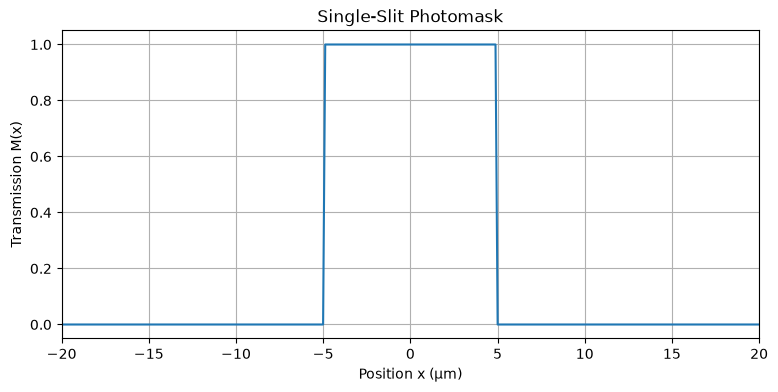

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# Physical parameters
wavelength = 500e-9  # Wavelength: 500 nm
slit_width = 10e-6   # Slit width: 10 micrometers
U0 = 1.0

# Spatial discretization
N = 8192
Lx = 1e-3
dx = Lx / N

x = (np.arange(N) - N // 2) * dx

# Photomask transmission function
M = np.where(np.abs(x) <= slit_width / 2, 1.0, 0.0)

# Field immediately after the photomask
U_mask = U0 * M

# Visualization
plt.figure(figsize=(9, 4))
plt.plot(x * 1e6, M)
plt.xlim(-20, 20)
plt.xlabel("Position x (µm)")
plt.ylabel("Transmission M(x)")
plt.title("Single-Slit Photomask")
plt.grid(True)
plt.show()



### 2.2 Numerical Propagation of the Optical Field

Having defined the photomask transmission function, we now calculate the propagation of the transmitted optical field.

The Angular Spectrum Method consists of three steps:

1. Compute the Fourier transform of the field immediately after the mask.
2. Multiply each spatial-frequency component by the propagation transfer function.
3. Apply the inverse Fourier transform to reconstruct the optical field.

The propagation transfer function is:

$$
H(k_x,z)=e^{ik_zz}
$$

where:

$$
k_z=\sqrt{k^2-k_x^2}
$$

with the physically appropriate branch for forward propagation and evanescent decay.

The optical intensity is proportional to:

$$
I(x,z)\propto |U(x,z)|^2
$$

We investigate how the diffraction pattern evolves at different propagation distances.


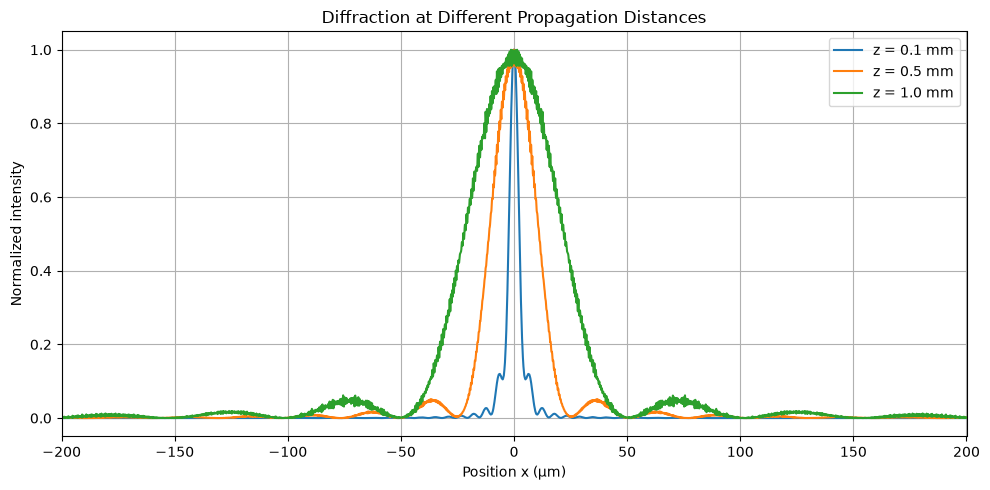

In [4]:

# Angular Spectrum Method

k = 2 * np.pi / wavelength

# Spatial-frequency grid
kx = 2 * np.pi * np.fft.fftfreq(N, d=dx)

# Longitudinal wavevector
kz = np.sqrt(k**2 - kx**2 + 0j)

# Fourier transform of the mask field
U_spectrum = np.fft.fft(U_mask)

# Propagation function
def propagate(z):
    H = np.exp(1j * kz * z)
    return np.fft.ifft(U_spectrum * H)

# Propagation distances
distances = [0.1e-3, 0.5e-3, 1e-3]

plt.figure(figsize=(10, 5))

for z in distances:
    Uz = propagate(z)
    intensity = np.abs(Uz)**2
    intensity /= intensity.max()

    plt.plot(
        x * 1e6,
        intensity,
        label=f"z = {z*1e3:.1f} mm"
    )

plt.xlim(-200, 200)
plt.xlabel("Position x (µm)")
plt.ylabel("Normalized intensity")
plt.title("Diffraction at Different Propagation Distances")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



### 2.3 Interpretation of the Numerical Results

The numerical results demonstrate the evolution of the diffraction pattern as the optical field propagates away from the photomask.

At short propagation distances, the intensity distribution exhibits near-field diffraction characteristics.

As the propagation distance increases, the central diffraction maximum becomes wider and secondary intensity maxima become visible.

In the far-field regime, the diffraction pattern approaches the characteristic squared sinc distribution predicted by Fraunhofer diffraction theory.

The approximate position of the first diffraction minimum is:

$$
x_1 \approx \frac{\lambda z}{a}
$$

For a wavelength of 500 nm, a slit width of 10 micrometers, and a propagation distance of 1 mm:

$$
x_1 \approx 50\,\mu\mathrm{m}
$$

The numerical results are consistent with the expected broadening of the diffraction pattern.

Small deviations may arise from finite sampling, numerical discretization, and the approximations involved in the analytical far-field model.

All three intensity profiles have been individually normalized to their maximum values to facilitate comparison of their spatial shapes.


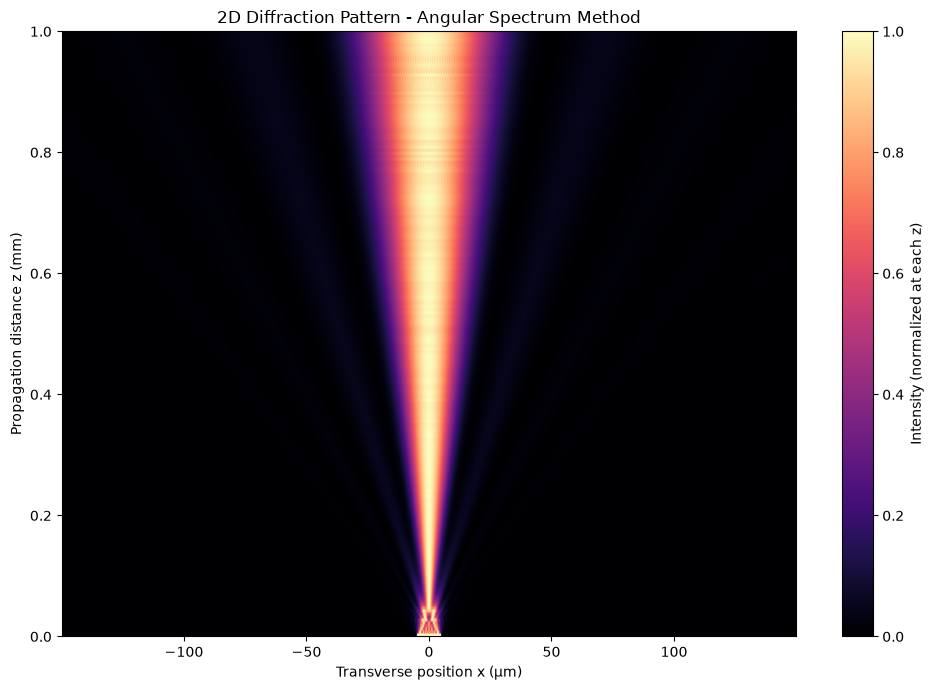

In [5]:

# 2D Diffraction Intensity Map

# Propagation from 0 to 1 mm
z_values = np.linspace(0, 1e-3, 201)

# Calculate intensity at each distance
intensity_map = np.array([
    np.abs(propagate(z))**2
    for z in z_values
])

# Normalize each distance separately for visualization
intensity_normalized = intensity_map / np.maximum(
    intensity_map.max(axis=1, keepdims=True),
    1e-12
)

# Show the central region
region = np.abs(x) <= 150e-6

plt.figure(figsize=(10, 7))

plt.imshow(
    intensity_normalized[:, region],
    extent=[
        x[region][0] * 1e6,
        x[region][-1] * 1e6,
        z_values[0] * 1e3,
        z_values[-1] * 1e3
    ],
    origin="lower",
    aspect="auto",
    cmap="magma"
)

plt.xlabel("Transverse position x (µm)")
plt.ylabel("Propagation distance z (mm)")
plt.title("2D Diffraction Pattern - Angular Spectrum Method")
plt.colorbar(label="Intensity (normalized at each z)")
plt.tight_layout()
plt.show()



### 2.4 Spatial Evolution of the Diffraction Pattern

The two-dimensional intensity map illustrates the spatial evolution of the optical field transmitted through the single-slit photomask.

Near the mask plane, the optical field is confined primarily to the transparent aperture.

As the propagation distance increases, diffraction causes the optical intensity distribution to spread in the transverse direction.

The central diffraction maximum becomes progressively wider, while weaker secondary maxima appear on both sides.

At sufficiently large propagation distances, the spatial intensity profile approaches the characteristic Fraunhofer diffraction pattern.

For visualization purposes, the intensity at each propagation distance has been normalized independently. Therefore, the map illustrates the evolution of the diffraction pattern rather than its absolute intensity.

These observations are consistent with the predictions of scalar diffraction theory and the Angular Spectrum Method.


RMSE: 0.009076
First minimum: ±50.00 µm


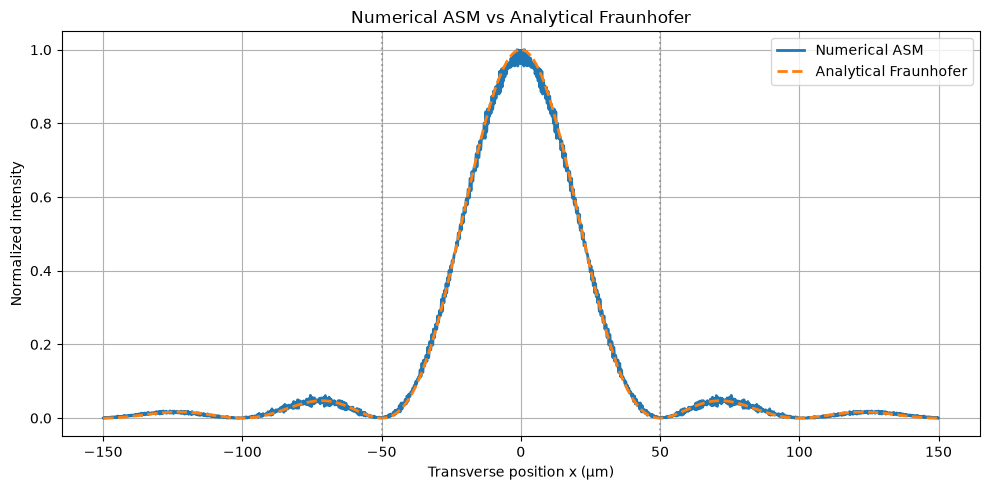

In [6]:

# Comparison: Numerical ASM vs Analytical Fraunhofer

z_test = 1e-3  # Propagation distance: 1 mm

# Numerical ASM intensity
U_num = propagate(z_test)
I_num = np.abs(U_num)**2
I_num = I_num / I_num.max()

# Analytical Fraunhofer intensity
beta = np.pi * slit_width * x / (wavelength * z_test)
I_analytical = np.sinc(beta / np.pi)**2

# Select observation region
region = np.abs(x) <= 150e-6

# Root Mean Square Error
rmse = np.sqrt(
    np.mean(
        (I_num[region] - I_analytical[region])**2
    )
)

# Predicted first diffraction minimum
x_min = wavelength * z_test / slit_width

print(f"RMSE: {rmse:.6f}")
print(f"First minimum: ±{x_min*1e6:.2f} µm")

# Visualization
plt.figure(figsize=(10, 5))

plt.plot(
    x[region] * 1e6,
    I_num[region],
    label="Numerical ASM",
    linewidth=2
)

plt.plot(
    x[region] * 1e6,
    I_analytical[region],
    "--",
    label="Analytical Fraunhofer",
    linewidth=2
)

plt.axvline(x_min * 1e6, color="gray",
            linestyle=":", alpha=0.6)
plt.axvline(-x_min * 1e6, color="gray",
            linestyle=":", alpha=0.6)

plt.xlabel("Transverse position x (µm)")
plt.ylabel("Normalized intensity")
plt.title("Numerical ASM vs Analytical Fraunhofer")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



### 2.5 Validation of the Numerical Model

The numerical Angular Spectrum Method (ASM) was compared with the analytical Fraunhofer diffraction model for a single-slit photomask.

The simulation parameters were:

- Wavelength: $\lambda = 500\,\mathrm{nm}$
- Slit width: $a = 10\,\mu\mathrm{m}$
- Propagation distance: $z = 1\,\mathrm{mm}$

Both intensity distributions were normalized to their respective maximum values.

The Root Mean Square Error (RMSE) was calculated as:

$$
\mathrm{RMSE} =
\sqrt{\frac{1}{N_s}
\sum_{j=1}^{N_s}
\left(I_{\mathrm{ASM},j}-I_{\mathrm{F},j}\right)^2}
$$

The obtained numerical result was:

$$
\boxed{\mathrm{RMSE}=0.009076}
$$

The theoretical position of the first diffraction minimum is approximately:

$$
x_1 = \frac{\lambda z}{a}
=50\,\mu\mathrm{m}
$$

The numerical and analytical intensity profiles exhibit very good agreement within the selected observation interval.

The small residual deviations may be attributed to finite sampling, numerical discretization, and the finite-distance approximation involved in the Fraunhofer model.

These results support the validity of the implemented ASM for the investigated diffraction configuration. Further convergence tests are required for a complete assessment of numerical accuracy.
